In [72]:
# GridSearchCV(
#     estimator,             # Model yang digunakan (misalnya, LinearRegression())
#     param_grid,            # Dictionary parameter yang akan diuji
#     scoring=None,          # Metrik evaluasi (default = accuracy untuk klasifikasi, r2 untuk regresi)
#     n_jobs=None,           # Jumlah CPU yang digunakan (-1 untuk semua CPU)
#     cv=None,               # Jumlah cross-validation (misalnya, 5 untuk 5-fold CV)
#     verbose=0,             # Level output log (0=diam, 1=beberapa info, 2=detail)
#     refit=True,            # Re-train model dengan parameter terbaik
#     return_train_score=False  # Jika True, hasil training score juga ditampilkan
# )

In [73]:
# RandomizedSearchCV(
#     estimator,             # Model yang digunakan
#     param_distributions,   # Dictionary parameter yang akan diuji (dipilih secara acak)
#     n_iter=10,             # Jumlah kombinasi parameter yang diuji
#     scoring=None,          # Metrik evaluasi (default = accuracy untuk klasifikasi, r2 untuk regresi)
#     n_jobs=None,           # Jumlah CPU yang digunakan (-1 untuk semua CPU)
#     cv=None,               # Jumlah cross-validation
#     random_state=None,     # Seed agar hasil tetap sama setiap eksekusi
#     verbose=0,             # Level output log
#     refit=True,            # Re-train model dengan parameter terbaik
#     return_train_score=False  # Jika True, hasil training score juga ditampilkan
# )

In [74]:
# BayesSearchCV(
#     estimator,             # Model yang digunakan
#     search_spaces,         # Dictionary parameter yang akan diuji
#     n_iter=50,             # Jumlah iterasi pencarian
#     scoring=None,          # Metrik evaluasi
#     n_jobs=-1,             # Gunakan semua CPU untuk mempercepat pencarian
#     cv=5,                  # Jumlah cross-validation
#     random_state=None,     # Seed agar hasil tetap sama
#     verbose=0,             # Level output log
#     refit=True             # Re-train model dengan parameter terbaik
# )

In [75]:
# HalvingGridSearchCV(
#     estimator,             # Model yang digunakan
#     param_grid,            # Dictionary parameter yang akan diuji
#     factor=3,              # Setiap iterasi, hanya 1/3 kandidat yang dipertahankan
#     min_resources='exhaust',  # Minimum data yang digunakan sebelum seleksi dilakukan
#     scoring=None,          # Metrik evaluasi
#     cv=None,               # Jumlah cross-validation
#     n_jobs=None,           # Jumlah CPU yang digunakan (-1 untuk semua CPU)
#     random_state=None,     # Seed agar hasil tetap sama
#     verbose=0,             # Level output log
#     refit=True             # Re-train model dengan parameter terbaik
# )

Cross validation

In [76]:
# from sklearn.model_selection import KFold

# kf = KFold(
#     n_splits=5,      # Jumlah fold (default = 5)
#     shuffle=False,   # Apakah data diacak sebelum dibagi (default = False)
#     random_state=None  # Seed untuk reproducibility
# )

In [77]:
# from sklearn.model_selection import StratifiedKFold

# skf = StratifiedKFold(
#     n_splits=5,      # Jumlah fold (default = 5)
#     shuffle=True,    # Apakah data diacak sebelum dibagi (default = False)
#     random_state=42  # Seed untuk reproducibility
# )

In [78]:
# from sklearn.model_selection import ShuffleSplit

# ss = ShuffleSplit(
#     n_splits=5,      # Jumlah iterasi pembagian (default = 10)
#     test_size=0.2,   # Proporsi data uji (20% dari dataset)
#     train_size=None, # Proporsi data latih (None = otomatis sisanya)
#     random_state=42  # Seed untuk reproducibility
# )

In [79]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.model_selection import cross_val_score, ShuffleSplit
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import MinMaxScaler
from skopt import BayesSearchCV
from collections import Counter
from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import HalvingGridSearchCV
from sklearn.metrics import r2_score

df = pd.read_csv("tesla.csv")
df.head()

,Date,Open,High,Low,Close,Adj Close,Volume
0,2010-06-29,3.800,5.000,3.508,4.778,4.778,93831500
1,2010-06-30,5.158,6.084,4.660,4.766,4.766,85935500
2,2010-07-01,5.000,5.184,4.054,4.392,4.392,41094000
3,2010-07-02,4.600,4.620,3.742,3.840,3.840,25699000
4,2010-07-06,4.000,4.000,3.166,3.222,3.222,34334500


In [80]:
x = df[['Open', 'High', 'Low']]
y = df[['Close']]

scaler_x = MinMaxScaler()
x_encode = scaler_x.fit_transform(x)

scaler_y = MinMaxScaler() 
y = scaler_y.fit_transform(y)

x_train, x_test, y_train, y_test = train_test_split(x_encode, y, 
                                                    test_size=0.3, 
                                                    random_state=42)

Function

In [82]:
def tuning_model(model, param):
    sf = ShuffleSplit(n_splits=5, test_size=0.2, random_state=42)

    grid_search = GridSearchCV(model, param, cv=sf, scoring='r2', n_jobs=-1)
    grid_search.fit(x_train, y_train)

    random_search = RandomizedSearchCV(model, param_distributions=param, 
                                    n_iter=4, 
                                    cv=sf, 
                                    scoring='r2', 
                                    n_jobs=-1, 
                                    random_state=42)

    random_search.fit(x_train, y_train)

    bayes_search = BayesSearchCV(model, param, cv=sf, 
                                scoring='r2', 
                                n_iter=4, 
                                n_jobs=-1, 
                                random_state=42)

    bayes_search.fit(x_train, y_train)

    hyperband = HalvingGridSearchCV(model, param, cv=sf, 
                                    factor=2, 
                                    scoring='r2', 
                                    n_jobs=-1)

    hyperband.fit(x_train, y_train)
    
    best_params_list = [
        grid_search.best_params_,
        random_search.best_params_,
        bayes_search.best_params_,
        hyperband.best_params_
    ]

    aggregated_params = {key: [params[key] for params in best_params_list] for key in param.keys()}
    
    return aggregated_params
    

In [83]:
model = LinearRegression()

param_grid = {
    'fit_intercept': [True, False],
    'copy_X': [True, False],
}

best_params = tuning_model(model, param_grid)

fit_intercept, copy_X = (
    Counter(best_params["fit_intercept"]).most_common(1)[0][0],
    Counter(best_params["copy_X"]).most_common(1)[0][0]
)

print(f"Best fit_intercept : {fit_intercept}")
print(f"Best copy_X : {copy_X}")


Best fit_intercept : False
Best copy_X : True


In [84]:
best_model = LinearRegression(copy_X=copy_X, fit_intercept=fit_intercept)

best_model.fit(x_train, y_train)

y_pred = best_model.predict(x_test)

r2 = r2_score(y_test, y_pred)

print(f"R² Score: {r2:.4f}")

R² Score: 0.9997


CEK OVERFITTING

In [85]:
# Evaluasi pada data training
y_train_pred = best_model.predict(x_train)
r2_train = r2_score(y_train, y_train_pred)

# Evaluasi pada data testing
y_test_pred = best_model.predict(x_test)
r2_test = r2_score(y_test, y_test_pred)

# Cetak hasil
print("R² Score Training:", r2_train)
print("R² Score Testing:", r2_test)

R² Score Training: 0.9997444807949968
R² Score Testing: 0.9997162822341232


In [86]:
scores = cross_val_score(best_model, x_encode, y, cv=sf, scoring='r2')

print("R² Scores :", scores)

R² Scores : [0.99964963 0.99979626 0.99964953 0.99973538 0.99974524]


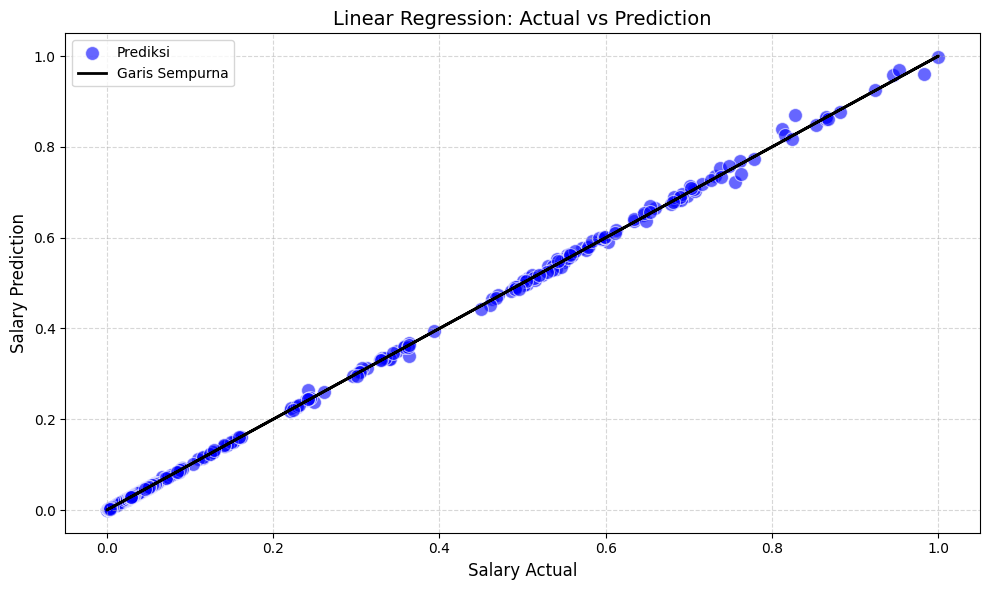

In [87]:
import matplotlib.pyplot as plt
import seaborn as sns

y_test_1d = np.ravel(y_test)
y_pred_1d = np.ravel(y_pred)

plt.figure(figsize=(10, 6))
sns.scatterplot(x=y_test_1d, y=y_pred_1d, color='blue', alpha=0.6, s=100, label='Prediksi')
plt.plot(y_test_1d, y_test_1d, color='black', linewidth=2, label='Garis Sempurna')
plt.xlabel('Salary Actual', fontsize=12)
plt.ylabel('Salary Prediction', fontsize=12)
plt.title('Linear Regression: Actual vs Prediction', fontsize=14)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [88]:
comparison_df = pd.DataFrame({
    'Actual': scaler_y.inverse_transform(y_test.reshape(-1, 1)).ravel(),
    'Predicted': scaler_y.inverse_transform(y_pred.reshape(-1, 1)).ravel()
})

comparison_df

,Actual,Predicted
0,59.860001,60.809207
1,45.122002,45.633119
2,46.882000,48.114413
3,43.686001,43.738921
4,55.318001,54.695217
...,...,...
882,41.080002,40.803264
883,39.130001,39.690242
884,161.882004,165.245636
885,7.398000,7.506471


HYPERPARAMETER DECISION TREE

In [89]:
from sklearn.tree import DecisionTreeRegressor

# Initialize model
model = DecisionTreeRegressor()

# Define hyperparameter grid
param_grid = {
    'criterion': ['friedman_mse', 'poisson'],
    'max_depth': [3, 5, 10, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2', None],
    'ccp_alpha' : [0, 0.05, 0.1]
}

aggregated_params = tuning_model(model, param_grid)

criterion, max_depth, max_features, min_samples_leaf, min_samples_split, ccp_alpha = (
    Counter(aggregated_params["criterion"]).most_common(1)[0][0],
    Counter(aggregated_params["max_depth"]).most_common(1)[0][0],
    Counter(aggregated_params["max_features"]).most_common(1)[0][0],
    Counter(aggregated_params["min_samples_leaf"]).most_common(1)[0][0],
    Counter(aggregated_params["min_samples_split"]).most_common(1)[0][0],
    Counter(aggregated_params["ccp_alpha"]).most_common(1)[0][0]
)

print(f"Best criterion : {criterion}")
print(f"Best max_depth : {max_depth}")
print(f"Best max_features : {max_features}")
print(f"Best min_samples_leaf : {min_samples_leaf}")
print(f"Best min_samples_split : {min_samples_split}")
print(f"Best ccp_alpha : {ccp_alpha}")


Best criterion : friedman_mse
Best max_depth : 10
Best max_features : None
Best min_samples_leaf : 2
Best min_samples_split : 2
Best ccp_alpha : 0


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/numpy/ma/core.py:2820: RuntimeWarning: invalid value encountered in cast
  _data = np.array(data, dtype=dtype, copy=copy,


In [90]:
# Train best model
best_model = DecisionTreeRegressor(criterion=criterion,
                                   max_depth=max_depth, 
                                   max_features=max_features,
                                   min_samples_leaf=min_samples_leaf,
                                   min_samples_split=min_samples_split,
                                   ccp_alpha=ccp_alpha,
                                   random_state=42)

best_model.fit(x_train, y_train)

# Make predictions
y_pred = best_model.predict(x_test)

# Evaluate model
r2 = r2_score(y_test, y_pred)
print(f"R² Score: {r2:.4f}")

R² Score: 0.9992


In [91]:
# Evaluasi pada data training
y_train_pred = best_model.predict(x_train)
r2_train = r2_score(y_train, y_train_pred)

# Evaluasi pada data testing
y_test_pred = best_model.predict(x_test)
r2_test = r2_score(y_test, y_test_pred)

# Cetak hasil
print("R² Score Training:", r2_train)
print("R² Score Testing:", r2_test)

R² Score Training: 0.9998971599652328
R² Score Testing: 0.9991606554594831


In [92]:
scores = cross_val_score(best_model, x_encode, y, cv=sf, scoring='r2')

print("R² Scores :", scores)

R² Scores : [0.99946473 0.99925587 0.99930464 0.99911481 0.99945939]
